# Task Description
Create a website the takes a movie review as an input and the review's sentiment (postive or negative) as the output

1. Import the dataset from kaggle

In [ ]:
import os

# Install Kaggle API client
!pip install kaggle

# Prompt user to upload kaggle.json
from google.colab import files
print("Please upload your kaggle.json API token.")
files.upload()

# Move kaggle.json to the correct directory and set permissions
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Define the dataset path
dataset_path = 'lakshmi25npathi/imdb-dataset-of-50k-movie-reviews'

# Download the dataset
print(f"Downloading dataset: {dataset_path}")
!kaggle datasets download -d {dataset_path}

# Get the list of downloaded files (assuming it's a zip file)
import zipfile
import glob

zip_files = glob.glob('*.zip')

if zip_files:
    zip_file_name = zip_files[0] # Assuming only one zip file is downloaded
    print(f"Unzipping {zip_file_name}...")
    with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
        zip_ref.extractall('.')
    print("Dataset unzipped successfully.")
    # Clean up the zip file
    !rm {zip_file_name}
else:
    print("No zip file found to unzip.")

print("Dataset extraction complete.")

Please upload your kaggle.json API token.


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
License(s): other
100% 25.7M/25.7M [00:03<00:00, 8.54MB/s]

Unzipping imdb-dataset-of-50k-movie-reviews.zip...
Dataset unzipped successfully.
Dataset extraction complete.


2. View the content of the IMDB dataset

In [ ]:
import pandas as pd

# Load the dataset into a pandas DataFrame
df = pd.read_csv('/content/IMDB Dataset.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


3. Split the dataset into training and testing sets. where `sentiment` is the target variable and `review` is the feature.

In [ ]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df['review']
y = df['sentiment']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

4. Text preprocessing

4.1. remove stopwords (except for negation), html tags, and stemmer

In [ ]:
!pip install nltk

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import re

# Download NLTK data
try:
    stopwords.words('english')
except LookupError:
    nltk.download('stopwords')
try:
    PorterStemmer().stem('running')
except LookupError:
    nltk.download('punkt')

# Initialize stemmer and stopwords
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

# Define negation words to explicitly keep during stopword removal
negation_words_to_preserve = ['no', 'nor', 'never', 'none', 'neither', 'hardly', 'scarcely', 'barely', "n't"]

# Remove these negation words from the stop_words set
stop_words = {word for word in stop_words if word not in negation_words_to_preserve}

def preprocess_text(text):
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Convert to lowercase
    text = text.lower()

    # Remove non-alphabetic characters and split into words
    words = re.findall(r'\b[a-z]+\b', text)

    # Remove stopwords and apply stemming
    processed_words = []
    for word in words:
        if word not in stop_words:
            processed_words.append(stemmer.stem(word))

    return ' '.join(processed_words)

print("Applying preprocessing to training data...")
X_train_processed = X_train.apply(preprocess_text)
print("Applying preprocessing to testing data...")
X_test_processed = X_test.apply(preprocess_text)

print("\nOriginal X_train (first 2 examples):")
display(X_train.head(2))

print("\nProcessed X_train (first 2 examples):")
display(X_train_processed.head(2))

print("Preprocessing complete. X_train_processed and X_test_processed are ready.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Applying preprocessing to training data...
Applying preprocessing to testing data...

Original X_train (first 2 examples):


,review
39087,That's what I kept asking myself during the ma...
30893,I did not watch the entire movie. I could not ...



Processed X_train (first 2 examples):


,review
39087,kept ask mani fight scream match swear gener m...
30893,watch entir movi could watch entir movi stop d...


Preprocessing complete. X_train_processed and X_test_processed are ready.



4.2. Display and remove similar frequency words for negative and positive datasets


Most Common Words in Positive Reviews:


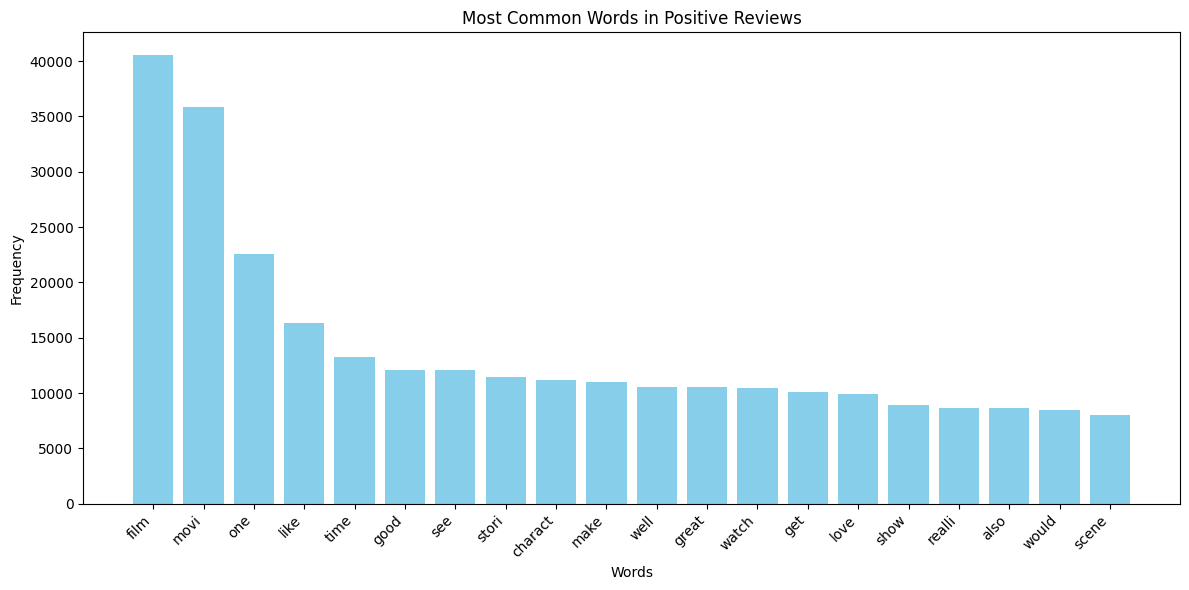


Most Common Words in Negative Reviews:


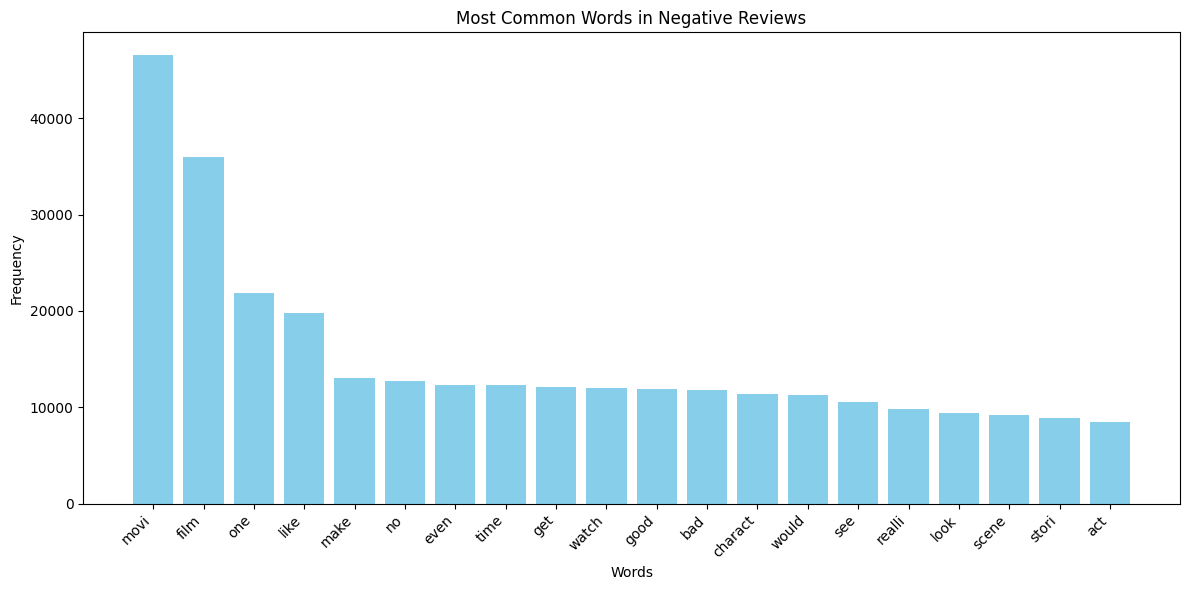

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

# Separate X_train_processed into positive and negative sentiments
X_train_positive_indices = y_train[y_train == 'positive'].index
X_train_negative_indices = y_train[y_train == 'negative'].index

X_train_positive_processed = X_train_processed.loc[X_train_positive_indices]
X_train_negative_processed = X_train_processed.loc[X_train_negative_indices]

# Function to get most common words for a given series of texts
def get_most_common_words(text_series, num_words=20):
    all_words = []
    for review in text_series:
        all_words.extend(review.split())
    word_counts = Counter(all_words)
    return word_counts.most_common(num_words)

# Get most common words for positive sentiment
common_words_positive = get_most_common_words(X_train_positive_processed)

# Get most common words for negative sentiment
common_words_negative = get_most_common_words(X_train_negative_processed)

# Plotting function
def plot_most_common_words(word_counts, title):
    words, counts = zip(*word_counts)
    plt.figure(figsize=(12, 6))
    plt.bar(words, counts, color='skyblue')
    plt.xlabel('Words')
    plt.ylabel('Frequency')
    plt.title(title)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# Plot for positive sentiment
print("\nMost Common Words in Positive Reviews:")
plot_most_common_words(common_words_positive, 'Most Common Words in Positive Reviews')

# Plot for negative sentiment
print("\nMost Common Words in Negative Reviews:")
plot_most_common_words(common_words_negative, 'Most Common Words in Negative Reviews')


In [ ]:
# User-specified words to explicitly remove
user_specified_words_to_remove = ["film", "movi"]

# The list of words to remove will ONLY consist of user-specified words
top_common_words = list(set(user_specified_words_to_remove))

print(f"Removing only the user-specified words: {', '.join(top_common_words)}.")

# Create a function to filter out these common words
def remove_top_common_words(text):
    words = text.split()
    filtered_words = [word for word in words if word not in top_common_words]
    return ' '.join(filtered_words)

print("\nApplying specified word removal to training data...")
X_train_processed_user = X_train_processed.apply(remove_top_common_words)

print("Applying specified word removal to testing data...")
X_test_processed_user = X_test_processed.apply(remove_top_common_words)

print("\nUpdated X_train_processed (first 2 examples):")
display(X_train_processed_user.head(2))

print("\nUpdated X_test_processed (first 2 examples):")
display(X_test_processed_user.head(2))

print("\nSpecified word removal complete. X_train_processed and X_test_processed are updated.")

Removing only the user-specified words: movi, film.

Applying specified word removal to training data...
Applying specified word removal to testing data...

Updated X_train_processed (first 2 examples):


,review
39087,kept ask mani fight scream match swear gener m...
30893,watch entir could watch entir stop dvd watch h...



Updated X_test_processed (first 2 examples):


,review
33553,realli like summerslam due look arena curtain ...
9427,mani televis show appeal quit mani differ kind...



Specified word removal complete. X_train_processed and X_test_processed are updated.


5. Model Training

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
import numpy as np

# 1. Label Encoding for target variable
print("Encoding target labels (positive/negative) to numerical (1/0)...")
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# 2. Tokenization and Padding
print("Tokenizing and padding text sequences for LSTM...")
# Max number of words to keep, based on word frequency
VOCAB_SIZE = 10000
# Max length of a sequence
MAX_LEN = 100

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<unk>")
tokenizer.fit_on_texts(X_train_processed_user)

X_train_sequences = tokenizer.texts_to_sequences(X_train_processed_user)
X_test_sequences = tokenizer.texts_to_sequences(X_test_processed_user)

X_train_padded = pad_sequences(X_train_sequences, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test_sequences, maxlen=MAX_LEN, padding='post', truncating='post')

# 3. Build the LSTM model
print("Building the LSTM model...")
embedding_dim = 128
lstm_units = 64

model = Sequential([
    Embedding(VOCAB_SIZE, embedding_dim, input_length=MAX_LEN),
    LSTM(lstm_units),
    Dense(1, activation='sigmoid') # Binary classification
])

# 4. Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

# 5. Train the model
print("Training the LSTM model...")
BATCH_SIZE = 64
EPOCHS = 5 # You can increase epochs for better performance, but it will take longer

history = model.fit(
    X_train_padded,
    y_train_encoded,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2 # Use a portion of training data for validation
)

# 6. Evaluate the model
print("Making predictions on the test set...")
y_pred_proba = model.predict(X_test_padded)
y_pred_encoded = (y_pred_proba > 0.5).astype(int)

# Generate and print the classification report
print("\nClassification Report for LSTM Model:")
print(classification_report(y_test_encoded, y_pred_encoded, target_names=label_encoder.classes_))

# Optional: Evaluate on the full test set
loss, accuracy = model.evaluate(X_test_padded, y_test_encoded, verbose=0)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Encoding target labels (positive/negative) to numerical (1/0)...
Tokenizing and padding text sequences for LSTM...
Building the LSTM model...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Training the LSTM model...
Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 72s 139ms/step - accuracy: 0.6529 - loss: 0.6279 - val_accuracy: 0.6453 - val_loss: 0.6366
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 70s 140ms/step - accuracy: 0.6720 - loss: 0.6188 - val_accuracy: 0.7420 - val_loss: 0.5658
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 141ms/step - accuracy: 0.8408 - loss: 0.3817 - val_accuracy: 0.8575 - val_loss: 0.3365
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 71s 141ms/step - accuracy: 0.9047 - loss: 0.2471 - val_accuracy: 0.8610 - val_loss: 0.3299
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 74s 148ms/step - accuracy: 0.9368 - loss: 0.1796 - val_accuracy: 0.8589 - val_loss: 0.3671
Making predictions on the test set...
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step

Classification Report for LSTM Model:
              precision    recall  f1-score   support

    negative       0.86      0.86      0.86      4961
    positive       0.86      0.87      0.86      5039

    accuracy                           0